# Ray Data: join two datasets

An inner join of two datasets on an id column. The second dataset is wired into the join node's right input.

**When to use it.** Enriching records with a lookup table, or combining features that live in different sources.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

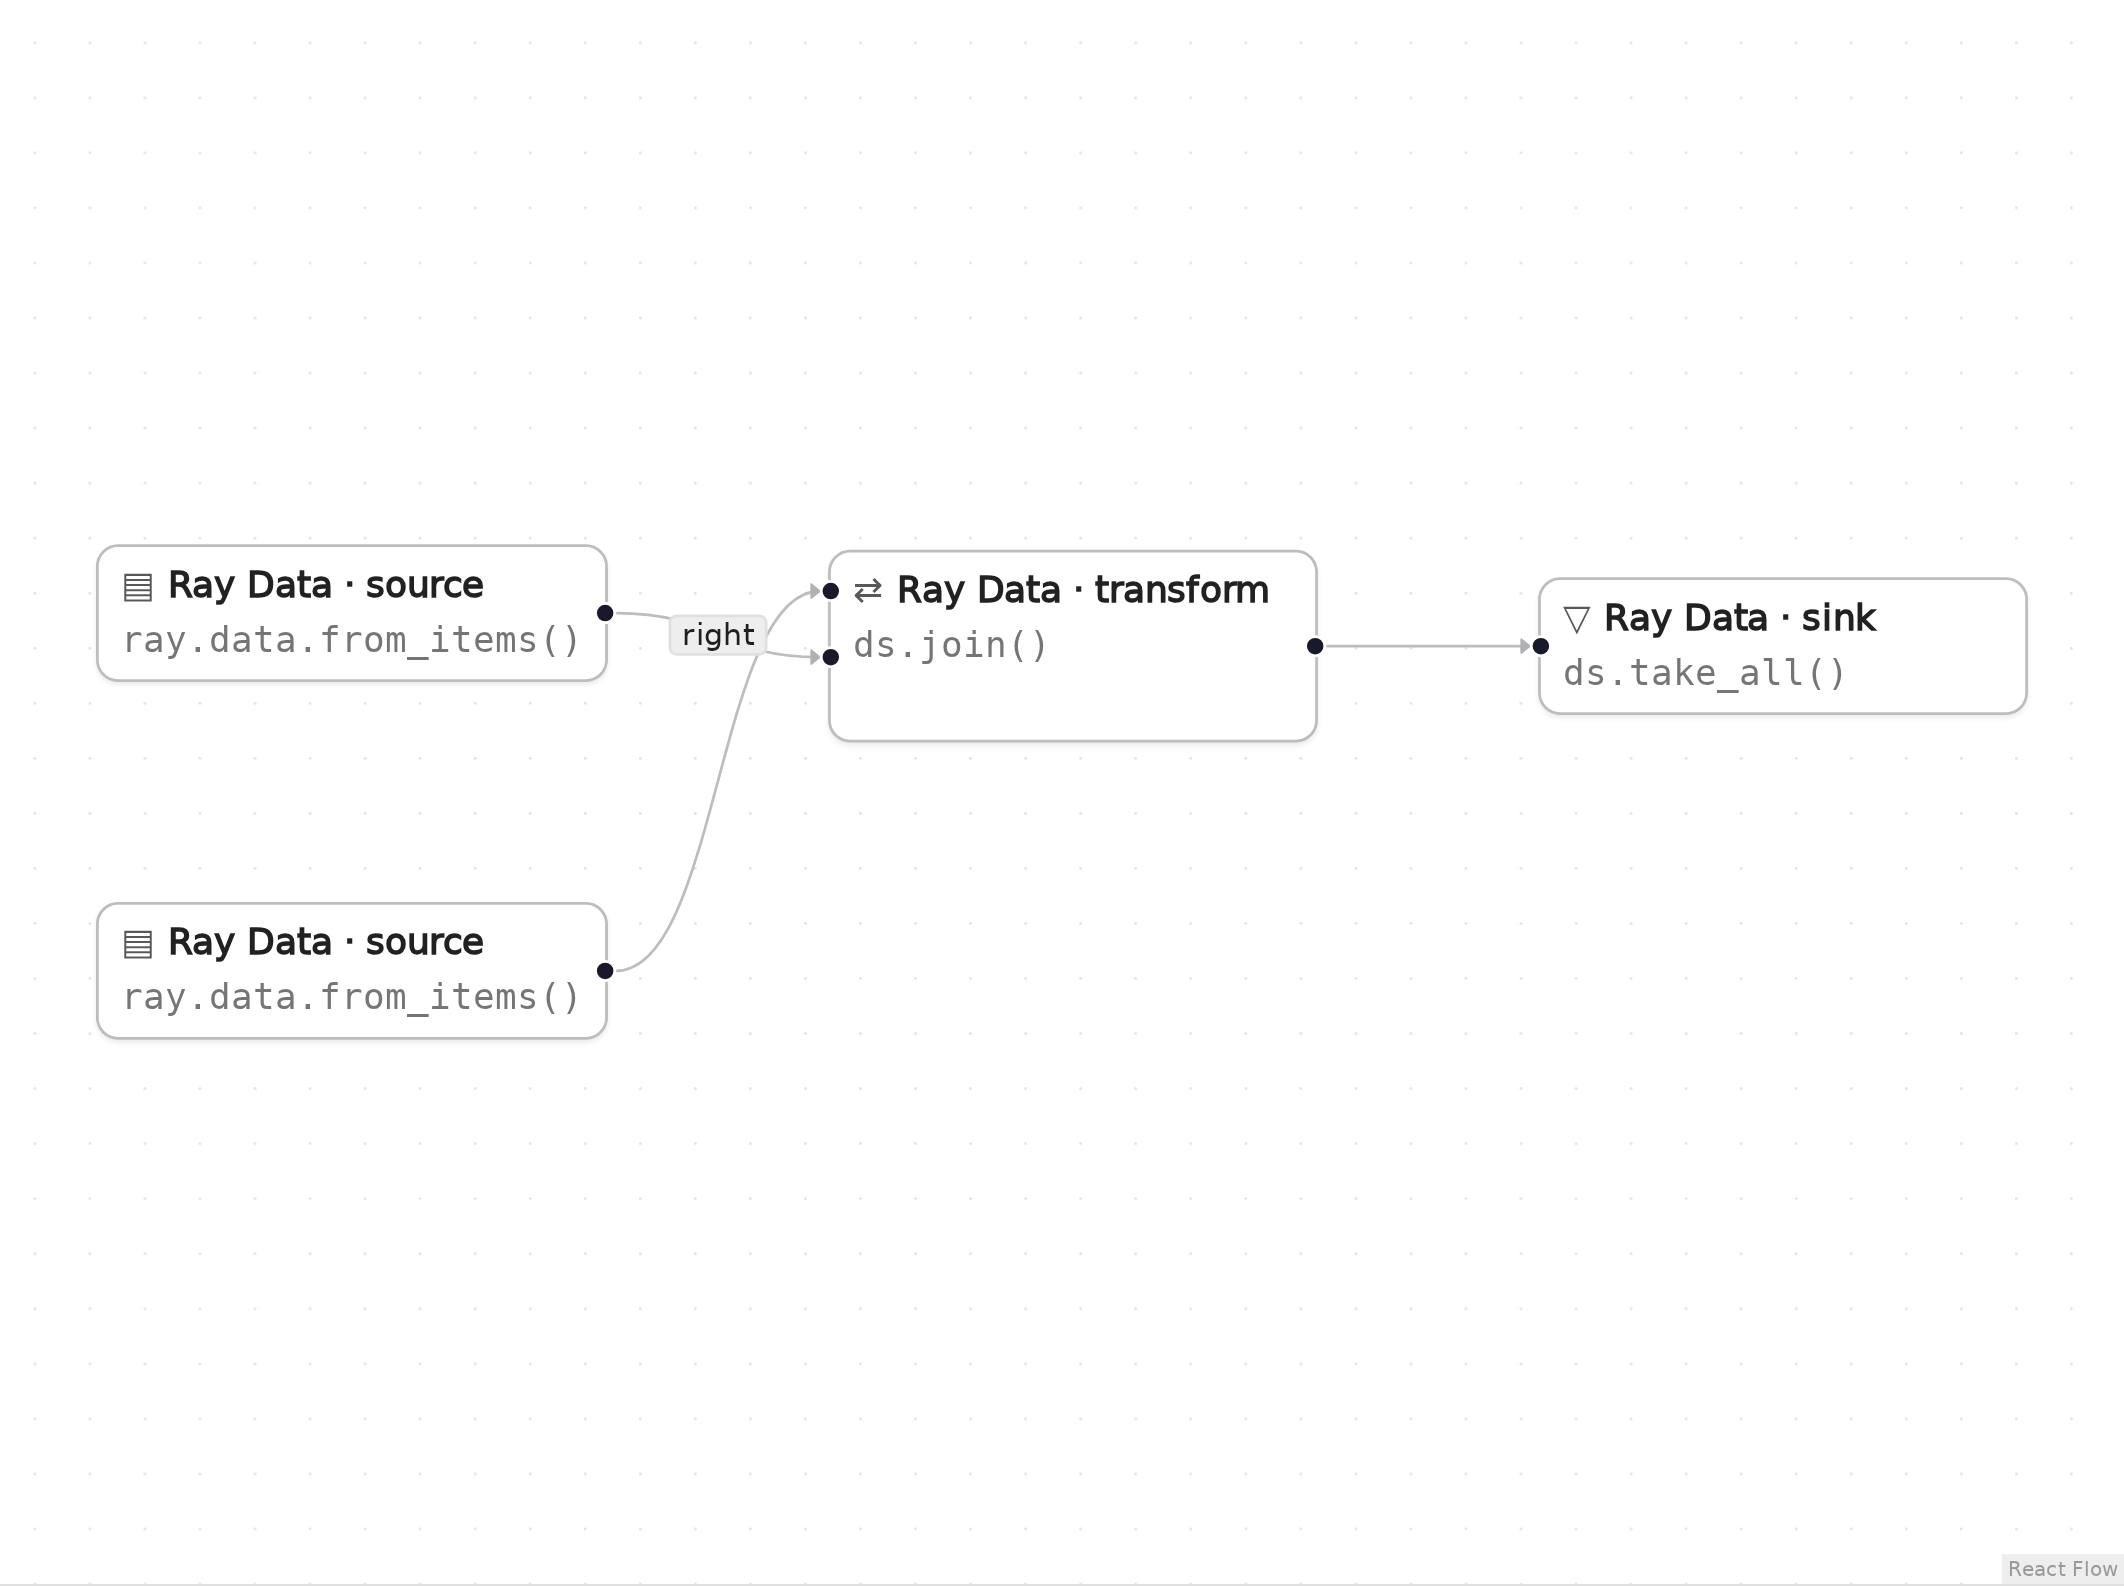

*The graph in Eugo's visual Ray builder.* Both sources show `ray.data.from_items()`. The upper one is the scores dataset (`n2`): its edge, labelled *right*, goes into the join's right input. The lower one is the people dataset (`n1`), the left side of the join. The two edges cross on the way in.

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

This pattern needs no user functions.

## Generated code

This is the cell the visual builder generated from the graph above.

In [2]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

ds_n1 = ray.data.from_items([{"id": 1, "name": "ada"}, {"id": 2, "name": "grace"}, {"id": 3, "name": "linus"}])
ds_n2 = ray.data.from_items([{"id": 1, "score": 90}, {"id": 3, "score": 75}])
ds_n3 = ds_n1.join(ds_n2, join_type="inner", num_partitions=2, on=("id",))
joined = ds_n3.take_all()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [3]:
joined = sorted(joined, key=lambda r: r["id"])
assert joined == [
    {"id": 1, "name": "ada", "score": 90},
    {"id": 3, "name": "linus", "score": 75},
], joined
print(joined)

[{'id': 1, 'name': 'ada', 'score': 90}, {'id': 3, 'name': 'linus', 'score': 75}]


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 8)

```python
ds_n1 = ray.data.from_items([{"id": 1, "name": "ada"}, {"id": 2, "name": "grace"}, {"id": 3, "name": "linus"}])
```

The left dataset: people.

**Source** (node `n2`, line 9)

```python
ds_n2 = ray.data.from_items([{"id": 1, "score": 90}, {"id": 3, "score": 75}])
```

The right dataset: scores, wired into the join's right-hand input.

**Transform** (node `n3`, line 10)

```python
ds_n3 = ds_n1.join(ds_n2, join_type="inner", num_partitions=2, on=("id",))
```

join(..., join_type="inner", on=("id",)) hash-partitions both sides into two partitions and keeps ids present in both.

**Sink** (node `n4`, line 11)

```python
joined = ds_n3.take_all()
```

take_all() collects the joined rows.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [4]:
ray.shutdown()